# **Regression Best Model Selection on the Concrete Dataset**
Target: `strength` (concrete compressive strength, MPa)

Models compared (each tuned with `GridSearchCV`, 5-fold CV):
1. Linear Regression
2. Polynomial Regression (tune `degree`)
3. Ridge (L2) (tune `alpha`)
4. Lasso (L1) (tune `alpha`)
5. Elastic Net (tune `alpha`, `l1_ratio`)
6. Bonus: Polynomial + Ridge / Lasso / ElasticNet (polynomial alone overfits, regularization fixes it)


### Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Dataset and Preprocessing

In [9]:
df = pd.read_csv('../1. Data_Preprocessing/For_Regression/concrete_after_preprocessing.csv')
print(df.shape)
df.head()

(1005, 9)


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
0,2.506120,-0.836598,-0.865363,-0.948723,-0.608250,0.846308,-1.207186,0.110360,79.986111
1,2.506120,-0.836598,-0.865363,-0.948723,-0.608250,1.039755,-1.207186,0.110360,61.887366
2,0.516534,0.818322,-0.865363,2.171753,-1.045223,-0.546505,-2.232243,2.126623,40.269535
3,0.516534,0.818322,-0.865363,2.171753,-1.045223,-0.546505,-2.232243,2.397748,41.052780
4,-0.767348,0.701026,-0.865363,0.469675,-1.045223,0.051889,0.661669,2.385338,44.296075


### Check Imbalance
In regression, imbalance means some target ranges have very few samples. We cut `strength` into 5 ranges and count them.

strength
<=20     19.5 %
20-35    32.2 %
35-50    29.1 %
50-65    13.9 %
>65       5.3 %
Name: count, dtype: str


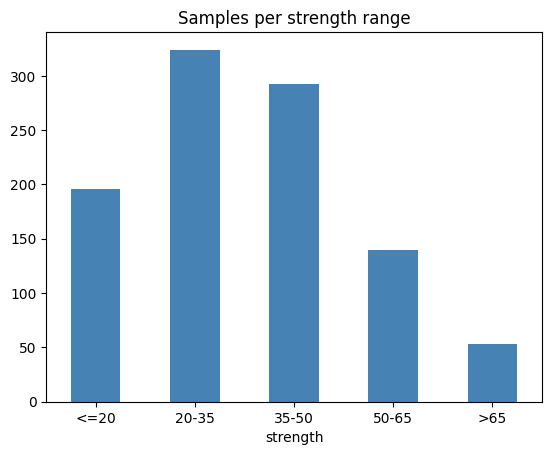

In [ ]:
bins = pd.cut(df['strength'], bins=[0, 20, 35, 50, 65, 100], labels=['<=20', '20-35', '35-50', '50-65', '>65'])

counts = bins.value_counts().sort_index()
print((counts / len(df) * 100).round(1).astype(str) + ' %')

counts.plot(kind='bar', color='steelblue', rot=0, title='Samples per strength range')
plt.show()

### Stratified Split + CV + Sample Weights
- **Stratified split / CV:** every split keeps the same low / mid / high strength ratio.
- **Sample weights (optional):** rare ranges get a bigger weight. Switch with `USE_WEIGHTS`.
  (We tested it: it improved error on high-strength samples but lowered the overall CV R2, so it is `False` by default.)

In [ ]:
#Select x and y
x = df.drop('strength', axis=1)
y = df['strength']

#Stratified train test split (stratify on strength ranges)
x_train, x_test, y_train, y_test, bins_train, bins_test = train_test_split(
    x, y, bins, test_size=0.2, random_state=42, stratify=bins)
print(x_train.shape, x_test.shape)

#Stratified 5-fold CV (same folds for every model)
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(x_train, bins_train))

#Sample weight = 1 / share of that range (rare range -> bigger weight)
def make_weights(b):
    w = 1 / b.map(b.value_counts(normalize=True)).astype(float)
    w = np.clip(w / w.mean(), 0.3, 3)
    return (w / w.mean()).to_numpy()

USE_WEIGHTS = False          # set True to train with sample weights
w_train = make_weights(bins_train)

(804, 8) (201, 8)


### Models and Hyperparameter Grids

In [ ]:
#Every model is a Pipeline, so the param names use the  step__param  format
#np.logspace gives alpha values 0.001, 0.01, 0.1 ... (right scale for regularization)
models = {
    'LinearRegression': (
        Pipeline([('scaler', StandardScaler()),
                  ('model', LinearRegression())]),
        {}   # no hyperparameter
    ),
    'PolynomialRegression': (
        Pipeline([('poly', PolynomialFeatures(include_bias=False)),
                  ('scaler', StandardScaler()),
                  ('model', LinearRegression())]),
        {'poly__degree': [1, 2, 3, 4]}
    ),
    'Ridge': (
        Pipeline([('scaler', StandardScaler()),
                  ('model', Ridge(random_state=42))]),
        {'model__alpha': np.logspace(-3, 3, 13)}
    ),
    'Lasso': (
        Pipeline([('scaler', StandardScaler()),
                  ('model', Lasso(max_iter=50000, random_state=42))]),
        {'model__alpha': np.logspace(-4, 1, 11)}
    ),
    'ElasticNet': (
        Pipeline([('scaler', StandardScaler()),
                  ('model', ElasticNet(max_iter=50000, random_state=42))]),
        {'model__alpha': np.logspace(-4, 1, 11),
         'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]}
    ),

    #Bonus: polynomial + regularization (less overfitting than plain polynomial)
    'Poly+Ridge': (
        Pipeline([('poly', PolynomialFeatures(include_bias=False)),
                  ('scaler', StandardScaler()),
                  ('model', Ridge(random_state=42))]),
        {'poly__degree': [2, 3], 'model__alpha': np.logspace(-2, 3, 11)}
    ),
    'Poly+Lasso': (
        Pipeline([('poly', PolynomialFeatures(include_bias=False)),
                  ('scaler', StandardScaler()),
                  ('model', Lasso(max_iter=50000, random_state=42))]),
        {'poly__degree': [2, 3], 'model__alpha': np.logspace(-3, 0, 7)}
    ),
    'Poly+ElasticNet': (
        Pipeline([('poly', PolynomialFeatures(include_bias=False)),
                  ('scaler', StandardScaler()),
                  ('model', ElasticNet(max_iter=50000, random_state=42))]),
        {'poly__degree': [2, 3], 'model__alpha': np.logspace(-3, 0, 7),
         'model__l1_ratio': [0.2, 0.5, 0.8]}
    ),
}

### GridSearchCV on every model

In [ ]:
%%time
all_model_results = []
best_estimators = {}

for name, (pipe, param_grid) in models.items():
    #GridSearchCV (stratified 5-fold cross validation)
    grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='r2', n_jobs=-1, return_train_score=True)
    fit_params = {'model__sample_weight': w_train} if USE_WEIGHTS else {}
    grid.fit(x_train, y_train, **fit_params)

    #Predict with the best estimator
    y_pred = grid.best_estimator_.predict(x_test)

    #Evaluate on the test set
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    high = y_test > 50                                   # rare high-strength samples
    mae_high = mean_absolute_error(y_test[high], y_pred[high])
    train_r2 = grid.cv_results_['mean_train_score'][grid.best_index_]

    print(name)
    print('MAE: ', round(mae, 4))
    print('MSE: ', round(mse, 4))
    print('RMSE: ', round(rmse, 4))
    print('R2: ', round(r2, 4))
    print('MAE (strength > 50): ', round(mae_high, 4))
    print('Best Params: ', grid.best_params_)
    print('Train R2: ', round(train_r2, 4), '| CV R2: ', round(grid.best_score_, 4))
    print('=' * 50)

    best_estimators[name] = grid.best_estimator_
    all_model_results.append({
        'Model': name,
        'MAE_Test': mae,
        'MSE_Test': mse,
        'RMSE_Test': rmse,
        'R2_Test': r2,
        'MAE_High(>50)': mae_high,
        'Best_Params_CV': grid.best_params_,
        'Train_R2': train_r2,
        'Best_Score_CV_R2': grid.best_score_
    })

LinearRegression
MAE:  5.5643
MSE:  53.9215
RMSE:  7.3431
R2:  0.7929
MAE (strength > 50):  9.2408
Best Params:  {}
Train R2:  0.8141 | CV R2:  0.8077


PolynomialRegression
MAE:  4.8919
MSE:  45.4038
RMSE:  6.7382
R2:  0.8256
MAE (strength > 50):  7.3938
Best Params:  {'poly__degree': 2}
Train R2:  0.8927 | CV R2:  0.8635


Ridge
MAE:  5.5637
MSE:  53.9005
RMSE:  7.3417
R2:  0.793
MAE (strength > 50):  9.2424
Best Params:  {'model__alpha': np.float64(0.1)}
Train R2:  0.8141 | CV R2:  0.8077


Lasso
MAE:  5.5643
MSE:  53.9195
RMSE:  7.343
R2:  0.7929
MAE (strength > 50):  9.2409
Best Params:  {'model__alpha': np.float64(0.0001)}
Train R2:  0.8141 | CV R2:  0.8077


ElasticNet
MAE:  5.563
MSE:  53.8734
RMSE:  7.3399
R2:  0.7931
MAE (strength > 50):  9.2444
Best Params:  {'model__alpha': np.float64(0.00031622776601683794), 'model__l1_ratio': 0.1}
Train R2:  0.8141 | CV R2:  0.8077


Poly+Ridge
MAE:  3.9258
MSE:  40.8972
RMSE:  6.3951
R2:  0.8429
MAE (strength > 50):  5.9934
Best Params:  {'model__alpha': np.float64(1.0), 'poly__degree': 3}
Train R2:  0.9528 | CV R2:  0.8927


Poly+Lasso
MAE:  3.8582
MSE:  29.2166
RMSE:  5.4052
R2:  0.8878
MAE (strength > 50):  5.347
Best Params:  {'model__alpha': np.float64(0.03162277660168379), 'poly__degree': 3}
Train R2:  0.9398 | CV R2:  0.8961


Poly+ElasticNet
MAE:  3.9204
MSE:  30.0374
RMSE:  5.4806
R2:  0.8846
MAE (strength > 50):  5.4388
Best Params:  {'model__alpha': np.float64(0.03162277660168379), 'model__l1_ratio': 0.8, 'poly__degree': 3}
Train R2:  0.9386 | CV R2:  0.8948
CPU times: user 21 s, sys: 21 ms, total: 21 s
Wall time: 21.2 s


### Best Model

In [ ]:
#Convert results to DataFrame and find the best model (selected by CV R2, not by the test set)
results_df = pd.DataFrame(all_model_results)
results_df_sorted = results_df.sort_values(by='Best_Score_CV_R2', ascending=False).reset_index(drop=True)

print("===== Overall Model Performance (Sorted by Cross-Validated R2 Score) =====")
display(results_df_sorted)

print("\n===== Best Overall Model =====")
best_model = results_df_sorted.iloc[0]
print(f"Model: {best_model['Model']}")
print(f"Cross-Validated R2 Score: {best_model['Best_Score_CV_R2']:.4f}")
print(f"Test R2 Score: {best_model['R2_Test']:.4f}")
print(f"Test MAE: {best_model['MAE_Test']:.4f}")
print(f"Test MAE (strength > 50): {best_model['MAE_High(>50)']:.4f}")
print(f"Best Parameters: {best_model['Best_Params_CV']}")

===== Overall Model Performance (Sorted by Cross-Validated R2 Score) =====


,Model,MAE_Test,MSE_Test,RMSE_Test,R2_Test,MAE_High(>50),Best_Params_CV,Train_R2,Best_Score_CV_R2
0,Poly+Lasso,3.858195,29.216630,5.405241,0.887770,5.346989,"{'model__alpha': 0.03162277660168379, 'poly__d...",0.939776,0.896126
1,Poly+ElasticNet,3.920398,30.037354,5.480634,0.884617,5.438761,"{'model__alpha': 0.03162277660168379, 'model__...",0.938621,0.894794
2,Poly+Ridge,3.925799,40.897211,6.395093,0.842901,5.993371,"{'model__alpha': 1.0, 'poly__degree': 3}",0.952799,0.892738
3,PolynomialRegression,4.891939,45.403849,6.738238,0.825590,7.393794,{'poly__degree': 2},0.892669,0.863469
4,ElasticNet,5.563000,53.873442,7.339853,0.793056,9.244361,"{'model__alpha': 0.00031622776601683794, 'mode...",0.814105,0.807722
5,Ridge,5.563735,53.900508,7.341697,0.792952,9.242359,{'model__alpha': 0.1},0.814107,0.807721
6,LinearRegression,5.564297,53.921495,7.343126,0.792871,9.240832,{},0.814108,0.807720
7,Lasso,5.564253,53.919536,7.342992,0.792879,9.240934,{'model__alpha': 0.0001},0.814108,0.807720



===== Best Overall Model =====
Model: Poly+Lasso
Cross-Validated R2 Score: 0.8961
Test R2 Score: 0.8878
Test MAE: 3.8582
Test MAE (strength > 50): 5.3470
Best Parameters: {'model__alpha': np.float64(0.03162277660168379), 'poly__degree': 3}


### Visualization

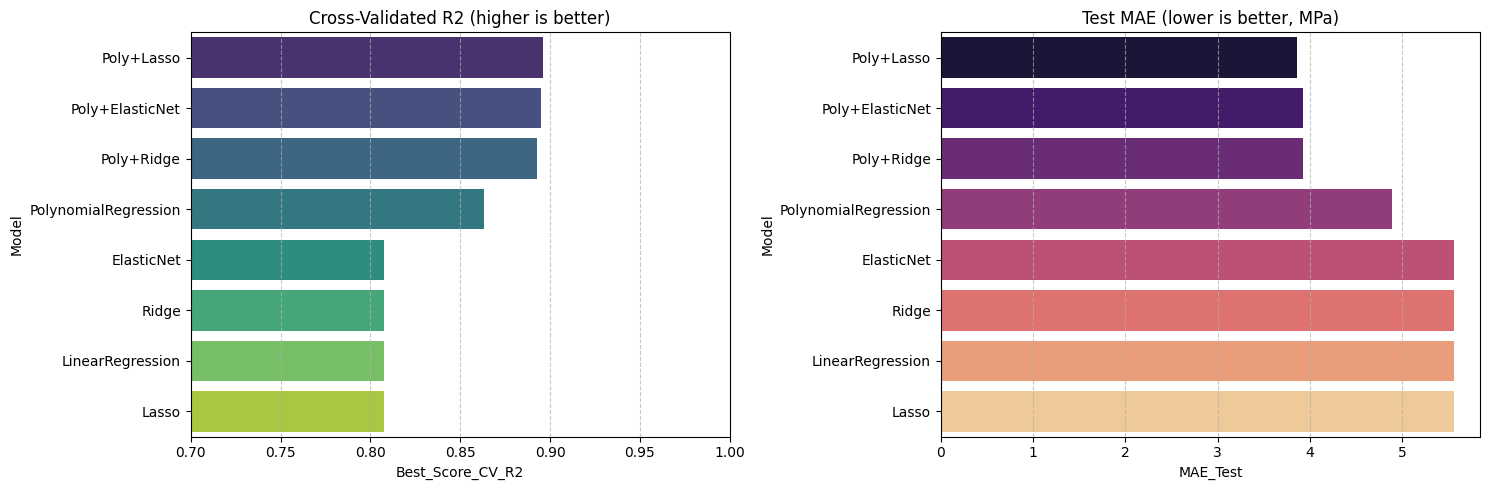

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

#CV R2 score
sns.barplot(x='Best_Score_CV_R2', y='Model', hue='Model', data=results_df_sorted, palette='viridis', legend=False, ax=ax[0])
ax[0].set_title('Cross-Validated R2 (higher is better)')
ax[0].set_xlim(0.7, 1)
ax[0].grid(axis='x', linestyle='--', alpha=0.7)

#Test MAE
sns.barplot(x='MAE_Test', y='Model', hue='Model', data=results_df_sorted, palette='magma', legend=False, ax=ax[1])
ax[1].set_title('Test MAE (lower is better, MPa)')
ax[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

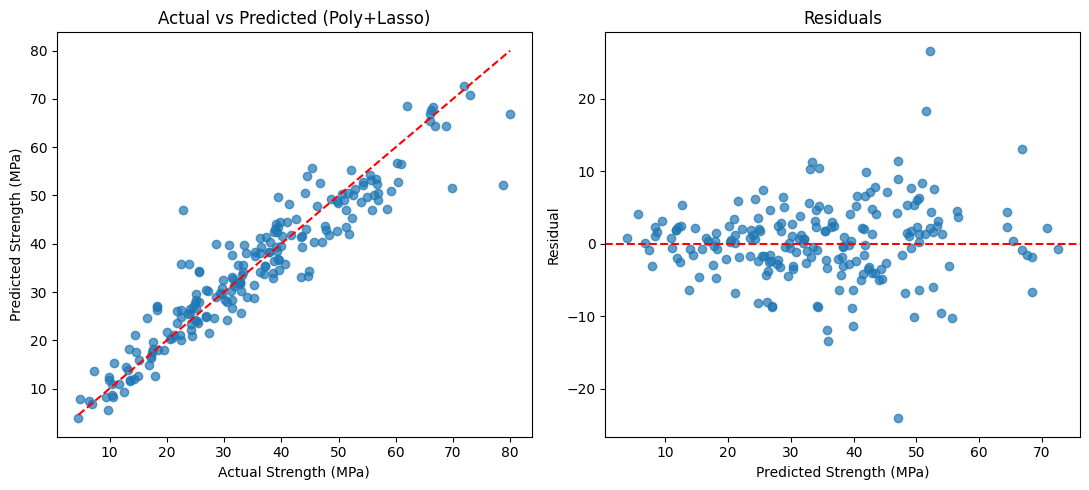

In [ ]:
#Actual vs Predicted + residuals for the best model
best_name = results_df_sorted.iloc[0]['Model']
y_pred_best = best_estimators[best_name].predict(x_test)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].scatter(y_test, y_pred_best, alpha=0.7)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
ax[0].set_xlabel('Actual Strength (MPa)'); ax[0].set_ylabel('Predicted Strength (MPa)')
ax[0].set_title(f'Actual vs Predicted ({best_name})')

ax[1].scatter(y_pred_best, y_test - y_pred_best, alpha=0.7)
ax[1].axhline(0, color='r', ls='--')
ax[1].set_xlabel('Predicted Strength (MPa)'); ax[1].set_ylabel('Residual')
ax[1].set_title('Residuals')
plt.tight_layout(); plt.show()

### Coefficients (Linear vs Ridge vs Lasso vs ElasticNet)

In [ ]:
#Lasso / ElasticNet push weak features to 0 (feature selection)
coef_df = pd.DataFrame({
    'Feature': x_train.columns,
    'Linear': best_estimators['LinearRegression'].named_steps['model'].coef_,
    'Ridge': best_estimators['Ridge'].named_steps['model'].coef_,
    'Lasso': best_estimators['Lasso'].named_steps['model'].coef_,
    'ElasticNet': best_estimators['ElasticNet'].named_steps['model'].coef_,
}).set_index('Feature')
coef_df.round(4)

,Linear,Ridge,Lasso,ElasticNet
Feature,,,,
cement,13.8654,13.8377,13.8627,13.8015
slag,9.8039,9.7771,9.8012,9.7420
fly_ash,6.2066,6.1820,6.2042,6.1500
water,-2.7165,-2.7356,-2.7186,-2.7606
superplasticizer,0.6379,0.6378,0.6376,0.6377
coarse_aggregate,2.1918,2.1724,2.1897,2.1469
fine_aggregate,2.9896,2.9647,2.9870,2.9321
age,10.4025,10.4000,10.4023,10.3966


### Final Model (save as package file)
The best pipeline (best params) is trained once more on **all data**, then saved with `joblib`.
The test scores above come from the model trained on the train split only.

In [ ]:
final_model = clone(best_estimators[best_name])

if USE_WEIGHTS:
    final_model.fit(x, y, model__sample_weight=make_weights(bins))
else:
    final_model.fit(x, y)

joblib.dump(final_model, 'concrete_model.pkl')
results_df_sorted.to_csv('model_results.csv', index=False)
print(final_model)
print('Saved: concrete_model.pkl, model_results.csv')

Pipeline(steps=[('poly', PolynomialFeatures(degree=3, include_bias=False)),
                ('scaler', StandardScaler()),
                ('model',
                 Lasso(alpha=np.float64(0.03162277660168379), max_iter=50000,
                       random_state=42))])
Saved: concrete_model.pkl, model_results.csv


### Load the saved model and predict

In [ ]:
model = joblib.load('concrete_model.pkl')

new_rows = x_test.iloc[:5]
print('Predicted strength:', model.predict(new_rows).round(2))
print('Actual strength   :', y_test.iloc[:5].round(2).values)

Predicted strength: [28.54 25.02 50.12 43.99 62.56]
Actual strength   : [26.86 18.29 44.14 44.33 69.84]


### Download the files (Google Colab only)

In [ ]:
try:
    from google.colab import files
    files.download('concrete_model.pkl')
    files.download('model_results.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
